# 10 – Auswertung: Wie gross ist das Delta?

**Ziel.** Die Fragen des Versuchs beantworten, einmal und nur an den Testblöcken:

| Nr. | Frage | Abschnitt |
| --- | --- | --- |
| 1 | Wie gut stimmt die gemeldete **Fläche** mit der Lösung überein? | 2 |
| 2 | Wie gut stimmt die **Anzahl** je Ausschnitt, verglichen mit einer ganz einfachen Schätzung? | 3 |
| 3 | Zählt die Methode bei **5 cm** besser als bei 10 cm, oder ist der Unterschied Zufall? | 4 |
| 4 | Wie gross ist das **Delta** zwischen Methode und amtlichen Daten, und woraus besteht es? | 5 und 6 |

**Warum.** Das ist der Zweck des ganzen Pilots (`01b`, Abschnitt 11). Es gibt keinen Zielwert, der erreicht werden muss: Berichtet wird, was herauskommt, mit seiner Unsicherheit.

**Eingestellt wird hier nichts.** Netz, Epoche, Schwelle und Zählformel standen fest, bevor die Testblöcke angesehen wurden.

**Zwei Nachträge vom 27.11.2026** (`01b`, Abschnitt 11.2). Beide ändern keine Zahl der ersten Auswertung:
- Sonderfelder (`✕`, `?`) sind zusätzlich getrennt ausgewiesen: Abschnitt 2 (Schritt 3), Abschnitt 3 (Schritt 5) und die Zähltabelle in Abschnitt 5.
- Der Lauf `A_10cm` wurde als Gegenprobe länger gelernt und ein zweites Mal ausgewertet. Das steht in Notebook 11, nicht hier.

**Eingaben:** `ergebnisse/zaehlung.csv` (Notebook 09), `ergebnisse/baseline.csv` (Notebook 06), Masken und Kategorie je Pixel für die Abbildung der Fehler.
**Ausgaben:** `ergebnisse/auswertung_laeufe.csv`, `ergebnisse/auswertung_delta.csv`, `ergebnisse/auswertung_bootstrap.csv`, Abbildungen `10_…`.

In [1]:
import json                        # Einstellungen lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
SEED, VERSUCHE = EINST["SEED"], EINST["VERSUCHE"]

import numpy as np                 # Rechnen und Zufall
import pandas as pd                # Tabellen
import matplotlib.pyplot as plt    # Abbildungen

LAEUFE = ["A_5cm", "A_10cm", "B_5cm", "B_10cm"]      # Reihenfolge in Tabellen und Abbildungen
FARBE = {5: "#257de0", 10: "#f47230"}                # Projektfarben der Auflösungen
ZIEHUNGEN = 10_000                                   # Wiederholungen des Bootstraps (Abschnitt 4)

## 1. Die Zahlen lesen

Eine Zeile je Lauf und Testausschnitt (Notebook 09). Die wichtigsten Spalten:

| Spalte | Bedeutung |
| --- | --- |
| `wahr`, `gezaehlt` | sichtbare Felder laut Ground Truth; gezählte Plätze der Methode (alle Felder) |
| `wahr_vergleich`, `gezaehlt_vergleich`, `amtlich` | dasselbe im Vergleichsraum (Strassenraum im Gebiet), dazu die amtliche Zahl |
| `tp`, `fp`, `fn` | Pixel: richtig erkannt, Fehlmeldung, übersehen |
| `wahr_kreuz`, `wahr_fragezeichen` | so viele der sichtbaren Felder sind Sonderfelder: `✕` (Taxi, Polizei, Feld mit Kreuz) und `?` (Invalidenparkplatz) |
| `tp_sonder`, `fn_sonder` | Pixel in Sonderfeldern: richtig erkannt, übersehen |

In [2]:
zaehlung = pd.read_csv(ERG / "zaehlung.csv")                         # Notebook 09
baseline = pd.read_csv(ERG / "baseline.csv").set_index("versuch")    # Notebook 06
print(f"{len(zaehlung)} Zeilen = {zaehlung.lauf.nunique()} Läufe × {zaehlung.kachel.nunique()} Testausschnitte in {zaehlung.block.nunique()} Blöcken")
zaehlung.groupby("lauf")[["wahr", "gezaehlt", "wahr_vergleich", "gezaehlt_vergleich", "amtlich"]].sum().loc[LAEUFE]

548 Zeilen = 4 Läufe × 137 Testausschnitte in 15 Blöcken


,wahr,gezaehlt,wahr_vergleich,gezaehlt_vergleich,amtlich
lauf,,,,,
A_5cm,708,664,360,351,354
A_10cm,708,626,360,336,354
B_5cm,500,454,266,258,275
B_10cm,500,395,266,210,275


## 2. Fläche: Stimmt, was das Netz meldet?

**Schritt 1: die Pixel aller Testausschnitte zusammenzählen.** Gezählt wurde in Notebook 09 nur auf bewerteten Pixeln (Lösung 0 oder 1).

- **Genauigkeit** = TP ÷ (TP + FP): Wenn das Netz Parkfläche meldet, stimmt es zu … %.
- **Trefferquote** = TP ÷ (TP + FN): Von aller sichtbaren Parkfläche findet es … %.
- **IoU** = TP ÷ (TP + FP + FN): Überdeckung von Meldung und Lösung.
- **Flächenverhältnis** = (TP + FP) ÷ (TP + FN): gemeldete Fläche ÷ wahre Fläche. Weil die Anzahl aus der Fläche folgt, zeigt diese Zahl schon, ob zu viel oder zu wenig gezählt wird.

Vorher: Pixelzahlen je Ausschnitt → nachher: vier Kennzahlen je Lauf.

In [3]:
summen = zaehlung.groupby("lauf")[["tp", "fp", "fn"]].sum().loc[LAEUFE]        # Pixel über alle Testausschnitte
flaeche = pd.DataFrame({
    "iou": summen.tp / (summen.tp + summen.fp + summen.fn),
    "genauigkeit": summen.tp / (summen.tp + summen.fp),
    "trefferquote": summen.tp / (summen.tp + summen.fn),
    "flaechenverhaeltnis": (summen.tp + summen.fp) / (summen.tp + summen.fn),
})
flaeche.round(3)

,iou,genauigkeit,trefferquote,flaechenverhaeltnis
lauf,,,,
A_5cm,0.618,0.783,0.745,0.951
A_10cm,0.582,0.774,0.701,0.906
B_5cm,0.569,0.759,0.694,0.914
B_10cm,0.487,0.738,0.589,0.797


**Schritt 2: dieselbe Kennzahl je Testblock.** Die Tabelle oben wirft alle Pixel zusammen. Blöcke mit viel Parkfläche zählen darin stärker als Blöcke mit wenig. Je Block gerechnet sieht man, wie verschieden die Blöcke sind.

Vorher: Pixelzahlen je Ausschnitt → nachher: IoU je Testblock und Lauf, daneben die Zahl der sichtbaren Felder.

In [4]:
je_block = zaehlung.groupby(["block", "lauf"])[["tp", "fp", "fn"]].sum()                        # Pixel je Testblock und Lauf
iou_block = (je_block.tp / (je_block.tp + je_block.fp + je_block.fn)).unstack("lauf")[LAEUFE]   # eine Spalte je Lauf
felder = zaehlung[zaehlung.aufloesung_cm == 5].pivot_table(index="block", columns="versuch", values="wahr", aggfunc="sum")   # sichtbare Felder je Block
iou_block.insert(0, "felder_B", felder.B)
iou_block.insert(0, "felder_A", felder.A)
gross = felder.A.nlargest(4)                                         # die vier Blöcke mit den meisten Feldern
print(f"Die 4 Blöcke mit den meisten Feldern enthalten {gross.sum() / felder.A.sum():.0%} aller sichtbaren Felder (Versuch A).")
iou_block.round(2)

Die 4 Blöcke mit den meisten Feldern enthalten 68% aller sichtbaren Felder (Versuch A).


lauf,felder_A,felder_B,A_5cm,A_10cm,B_5cm,B_10cm
block,,,,,,
2,0,0,0.00,0.00,0.00,0.00
7,105,78,0.72,0.68,0.58,0.57
10,33,33,0.69,0.69,0.69,0.62
11,8,0,0.72,0.72,0.00,0.00
17,74,51,0.53,0.45,0.46,0.28
18,0,0,NaN,NaN,0.00,NaN
21,95,70,0.63,0.61,0.62,0.55
28,39,39,0.59,0.52,0.46,0.37
37,136,67,0.59,0.53,0.50,0.36


**Wie man die Tabelle liest.** Eine Zeile je Testblock. `felder_A` und `felder_B` sind die sichtbaren Felder im Bild 2021 und 2024/25. Hat ein Block keine sichtbaren Felder, gibt es dort nichts zu finden: Die IoU ist dann 0 (es gibt nur Fehlmeldungen) oder leer (`NaN`: keine Felder und keine Meldung). Die IoU über alle Pixel (Schritt 1) wird vor allem von den wenigen Blöcken mit vielen Feldern bestimmt.

**Schritt 3: gewöhnliche Felder und Sonderfelder getrennt.** Sonderfelder sind die Formen `✕` (Taxi, Polizei, Feld mit Kreuz) und `?` (Invalidenparkplatz). Sie zählen wie gewöhnliche Felder (`01b`, 8.5 D4) und sind in allen Zahlen oben enthalten. Hier steht die **Trefferquote** getrennt: Wie viel der Fläche gewöhnlicher Felder findet das Netz, und wie viel der Fläche von Sonderfeldern? Genauigkeit und IoU lassen sich so nicht trennen, weil eine Fehlmeldung zu keinem Feld gehört.

Diese Auswertung kam am 27.11.2026 dazu (`01b`, Abschnitt 11.2, N1). Sie rechnet mit denselben Meldungen wie alles andere; eingestellt wurde nichts.

Vorher: Pixelzahlen je Ausschnitt → nachher: Trefferquote je Lauf, getrennt nach gewöhnlichen Feldern und Sonderfeldern.

In [5]:
pixel_form = zaehlung.groupby("lauf")[["tp", "fn", "tp_sonder", "fn_sonder"]].sum().loc[LAEUFE]      # Pixel über alle Testausschnitte
tp_gewoehnlich, fn_gewoehnlich = pixel_form.tp - pixel_form.tp_sonder, pixel_form.fn - pixel_form.fn_sonder   # der Rest sind gewöhnliche Felder
nach_form = pd.DataFrame({
    "trefferquote_gewoehnlich": tp_gewoehnlich / (tp_gewoehnlich + fn_gewoehnlich),
    "trefferquote_sonder": pixel_form.tp_sonder / (pixel_form.tp_sonder + pixel_form.fn_sonder),
    "anteil_sonder_an_der_flaeche": (pixel_form.tp_sonder + pixel_form.fn_sonder) / (pixel_form.tp + pixel_form.fn),
})
nach_form.round(3)

,trefferquote_gewoehnlich,trefferquote_sonder,anteil_sonder_an_der_flaeche
lauf,,,
A_5cm,0.762,0.523,0.071
A_10cm,0.724,0.399,0.071
B_5cm,0.711,0.466,0.068
B_10cm,0.615,0.225,0.068


**Wie man die Tabelle liest.** `anteil_sonder_an_der_flaeche` sagt, welcher Teil der sichtbaren Parkfläche zu Sonderfeldern gehört. Ist `trefferquote_sonder` tiefer als `trefferquote_gewoehnlich`, findet das Netz Sonderfelder schlechter als gewöhnliche Felder.

**Was die Tabelle zeigt** (Auswertung vom 27.11.2026). Sonderfelder machen rund 7 % der sichtbaren Parkfläche aus. In allen vier Läufen findet das Netz von ihrer Fläche einen deutlich kleineren Teil als von der Fläche gewöhnlicher Felder. Die Ursache ist nicht untersucht. Sonderfelder sind seltener und meist gelb statt weiss markiert; ob es daran liegt, zeigt diese Auswertung nicht.

## 3. Anzahl: Stimmt die Zählung je Ausschnitt?

**Schritt 1: der Fehler je Ausschnitt.** Fehler = gezählt − wahr. Zwei Kennzahlen (`01b`, 7.9):
- **MAE**: mittlerer Betrag des Fehlers. Um wie viele Plätze liegt die Zählung je Ausschnitt im Mittel daneben?
- **Bias**: Summe gezählt ÷ Summe wahr − 1. Minus heisst: insgesamt zu wenig gezählt.

**Schritt 2: die Baselines auf denselben Ausschnitten.** B0 schätzt überall 0; B1 schätzt überall den Durchschnitt der Lern-Ausschnitte (Notebook 06).

**Schritt 3: die Untergrenze.** `mae_formel` ist der Fehler der Zählformel allein: was sie zählt, wenn man ihr das perfekte Lösungsblatt der Testausschnitte gibt (Notebook 09). Viel kleiner als das kann die MAE eines Netzes nicht werden. Die MAE des Netzes liegt also zwischen `mae_formel` (bestmöglich) und `mae_b0` (ohne Bild).

**Schritt 4: nur Ausschnitte mit Feldern.** Viele Testausschnitte enthalten kein einziges sichtbares Feld. Dort ist "0 gezählt" richtig, und das macht die MAE über alle Ausschnitte klein. `mae_mit_feldern` ist die MAE nur über die Ausschnitte mit mindestens einem sichtbaren Feld (`ausschnitte_mit_feldern`). Sie zeigt, wie gut dort gezählt wird, wo es etwas zu zählen gibt.

**Schritt 5: Sonderfelder.** In `wahr` sind auch die Sonderfelder enthalten. `wahr_kreuz` und `wahr_fragezeichen` sagen, wie viele es sind. Was die Methode zählt, lässt sich nicht nach Form trennen: Eine gemeldete Fläche trägt keine Form. Wie gut die Fläche der Sonderfelder gefunden wird, steht in Abschnitt 2, Schritt 3.

Vorher: Zeilen je Ausschnitt → nachher: MAE und Bias je Lauf, daneben die MAE der Baselines.

In [6]:
zaehlung["fehler"] = zaehlung.gezaehlt - zaehlung.wahr               # Fehler der Methode je Ausschnitt
zeilen = []
for lauf in LAEUFE:
    teil = zaehlung[zaehlung.lauf == lauf]
    b1 = baseline.b1_je_ausschnitt[lauf[0]]                          # B1 des Versuchs ("A_5cm" -> "A")
    mit = teil[teil.wahr > 0]                                        # nur Ausschnitte mit sichtbaren Feldern
    zeilen.append({"lauf": lauf, "ausschnitte": len(teil), "wahr": teil.wahr.sum(), "gezaehlt": teil.gezaehlt.sum(),
                   "mae": teil.fehler.abs().mean(), "bias": teil.gezaehlt.sum() / teil.wahr.sum() - 1,
                   "mae_formel": (teil.gezaehlt_loesung - teil.wahr).abs().mean(),               # Formel am perfekten Lösungsblatt (Notebook 09)
                   "mae_b0": teil.wahr.abs().mean(), "mae_b1": (b1 - teil.wahr).abs().mean(),
                   "ausschnitte_mit_feldern": len(mit), "mae_mit_feldern": mit.fehler.abs().mean(), "felder_je_ausschnitt_mit_feldern": mit.wahr.mean(),
                   "wahr_kreuz": teil.wahr_kreuz.sum(), "wahr_fragezeichen": teil.wahr_fragezeichen.sum()})              # Schritt 5: davon Sonderfelder
anzahl = pd.DataFrame(zeilen).set_index("lauf")
anzahl.round(3)

,ausschnitte,wahr,gezaehlt,mae,bias,mae_formel,mae_b0,mae_b1,ausschnitte_mit_feldern,mae_mit_feldern,felder_je_ausschnitt_mit_feldern,wahr_kreuz,wahr_fragezeichen
lauf,,,,,,,,,,,,,
A_5cm,137,708,664,0.861,-0.062,0.321,5.168,5.172,77,1.338,9.195,44,7
A_10cm,137,708,626,1.109,-0.116,0.314,5.168,5.172,77,1.818,9.195,44,7
B_5cm,137,500,454,0.847,-0.092,0.190,3.650,3.857,67,1.493,7.463,30,5
B_10cm,137,500,395,1.263,-0.210,0.190,3.650,3.857,67,2.418,7.463,30,5


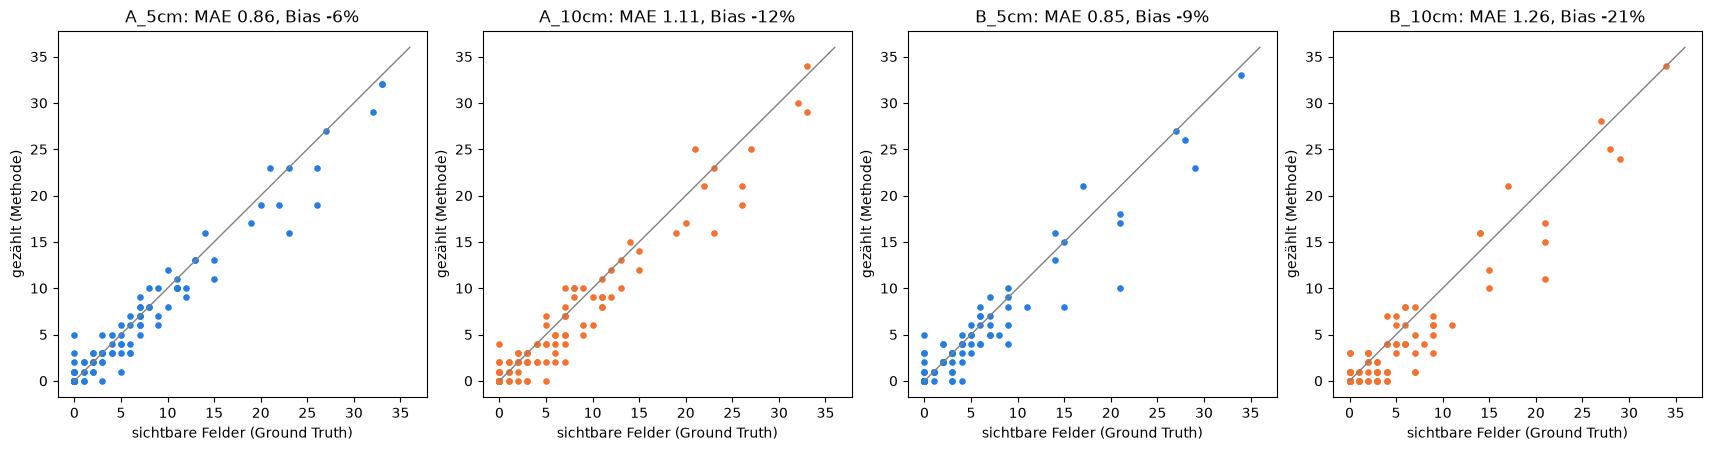

In [7]:
# Abbildung: gezählt gegen wahr je Testausschnitt, für alle vier Läufe. Punkte auf der Diagonale = richtig gezählt.
fig, achsen = plt.subplots(1, 4, figsize=(17, 4.4), layout="constrained")
grenze = max(zaehlung.wahr.max(), zaehlung.gezaehlt.max()) + 2
for ax, lauf in zip(achsen, LAEUFE):
    teil = zaehlung[zaehlung.lauf == lauf]
    ax.scatter(teil.wahr, teil.gezaehlt, s=14, color=FARBE[teil.aufloesung_cm.iloc[0]])
    ax.plot([0, grenze], [0, grenze], color="grey", linewidth=1)     # Diagonale: gezählt = wahr
    ax.set_title(f"{lauf}: MAE {anzahl.mae[lauf]:.2f}, Bias {anzahl.bias[lauf]:+.0%}")
    ax.set_xlabel("sichtbare Felder (Ground Truth)"); ax.set_ylabel("gezählt (Methode)")
fig.savefig(ABB / "10_gezaehlt_gegen_wahr.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jeder Punkt ist ein Testausschnitt. Auf der grauen Linie stimmt die Zählung genau. Punkte **unter** der Linie: zu wenig gezählt. Punkte **über** der Linie: zu viel.

**Zum Einordnen.** Die Spalte `mae_formel` der Tabelle oben ist die Untergrenze: der Fehler der Zählformel am perfekten Lösungsblatt.

## 4. 5 cm gegen 10 cm: echt oder Zufall?

**Worum es geht.** Beide Auflösungen wurden an **denselben** Ausschnitten geprüft. Darum vergleichen wir gepaart, Ausschnitt für Ausschnitt (`01b`, 7.9):

$$D = |\text{Fehler bei 10 cm}| - |\text{Fehler bei 5 cm}|$$

$D > 0$ heisst: In diesem Ausschnitt zählt 5 cm besser. Der Mittelwert $\bar D$ über alle Ausschnitte ist der Vorteil von 5 cm in Plätzen je Ausschnitt.

**Wie sicher ist $\bar D$?** Wir haben nur 15 Testblöcke. Mit anderen Blöcken käme ein etwas anderer Wert heraus. Der **Bootstrap** ahmt das nach: Aus den 15 Blöcken werden 15 gezogen, **mit Zurücklegen** (manche doppelt, manche gar nicht), und $\bar D$ wird neu gerechnet. Das wiederholen wir 10'000-mal. Die mittleren 95 % dieser Werte sind das Unsicherheitsintervall.

Gezogen werden **ganze Blöcke**, nicht einzelne Ausschnitte: Ausschnitte desselben Blocks zeigen dieselbe Strasse und sind nicht unabhängig (`01b`, 7.9).

**Schritt 1: $D$ je Ausschnitt, an Versuch A.**

In [8]:
def paare(versuch):
    # Je Testausschnitt der Betrag des Fehlers bei 5 cm und bei 10 cm nebeneinander, dazu D
    teil = zaehlung[zaehlung.versuch == versuch].assign(betrag=zaehlung.fehler.abs())
    tabelle = teil.pivot(index="kachel", columns="aufloesung_cm", values="betrag")   # Spalten 5 und 10
    tabelle["block"] = teil.drop_duplicates("kachel").set_index("kachel").block
    tabelle["D"] = tabelle[10] - tabelle[5]                          # positiv: 5 cm zählt besser
    return tabelle

paare_a = paare("A")
print(f"Versuch A: {len(paare_a)} Ausschnitte | 5 cm besser: {int((paare_a.D > 0).sum())} | gleich: {int((paare_a.D == 0).sum())} | 10 cm besser: {int((paare_a.D < 0).sum())}")
print(f"Mittel von D: {paare_a.D.mean():+.3f} Plätze je Ausschnitt")

Versuch A: 137 Ausschnitte | 5 cm besser: 39 | gleich: 80 | 10 cm besser: 18
Mittel von D: +0.248 Plätze je Ausschnitt


**Schritt 2: eine Ziehung vorgeführt.** `rng.choice(bloecke, size=15, replace=True)` zieht 15 Blöcke mit Zurücklegen. Für die gezogenen Blöcke werden alle ihre Ausschnitte genommen und $\bar D$ gerechnet.

In [9]:
rng = np.random.default_rng(SEED)                                    # Zufallsgenerator mit festem Startwert
bloecke = paare_a.block.unique()
gezogen = rng.choice(bloecke, size=len(bloecke), replace=True)       # eine Ziehung
mittel = np.mean(np.concatenate([paare_a.D[paare_a.block == block].values for block in gezogen]))
print("Blöcke:", sorted(bloecke.tolist()))
print("eine Ziehung:", sorted(gezogen.tolist()), f"→ Mittel von D: {mittel:+.3f}")

Blöcke: [2, 7, 10, 11, 17, 18, 21, 28, 37, 39, 46, 51, 52, 53, 56]
eine Ziehung: [2, 11, 17, 17, 17, 18, 18, 28, 28, 39, 39, 39, 51, 52, 56] → Mittel von D: +0.060


**Schritt 3: 10'000 Ziehungen, beide Versuche.** Damit es schnell geht, rechnen wir je Block vorab die Summe von $D$ und die Zahl seiner Ausschnitte. Für eine Ziehung ist $\bar D$ dann: Summe der gezogenen Summen ÷ Summe der gezogenen Anzahlen. `np.percentile` liefert die Grenzen des mittleren 95-%-Bereichs.

Vorher: $D$ je Ausschnitt → nachher: je Versuch $\bar D$ mit Intervall.

In [10]:
def bootstrap_mittel(werte, block, ziehungen=ZIEHUNGEN):
    # Zieht ganze Blöcke mit Zurücklegen und gibt für jede Ziehung das Mittel der Werte zurück
    je_block = pd.DataFrame({"wert": werte, "block": block}).groupby("block").wert.agg(["sum", "size"])
    rng = np.random.default_rng(SEED)
    gezogen = rng.integers(0, len(je_block), size=(ziehungen, len(je_block)))        # Nummern der gezogenen Blöcke
    return je_block["sum"].values[gezogen].sum(axis=1) / je_block["size"].values[gezogen].sum(axis=1)

zeilen, verteilungen = [], {}
for versuch in VERSUCHE:
    tabelle = paare(versuch)
    verteilungen[versuch] = bootstrap_mittel(tabelle.D.values, tabelle.block.values)
    unten, oben = np.percentile(verteilungen[versuch], [2.5, 97.5])
    zeilen.append({"versuch": versuch, "mae_5cm": tabelle[5].mean(), "mae_10cm": tabelle[10].mean(), "D_mittel": tabelle.D.mean(),
                   "intervall_unten": unten, "intervall_oben": oben, "intervall_ohne_null": bool(unten > 0 or oben < 0)})
bootstrap = pd.DataFrame(zeilen).set_index("versuch")
bootstrap.to_csv(ERG / "auswertung_bootstrap.csv")
bootstrap.round(3)

,mae_5cm,mae_10cm,D_mittel,intervall_unten,intervall_oben,intervall_ohne_null
versuch,,,,,,
A,0.861,1.109,0.248,0.059,0.459,True
B,0.847,1.263,0.416,0.143,0.657,True


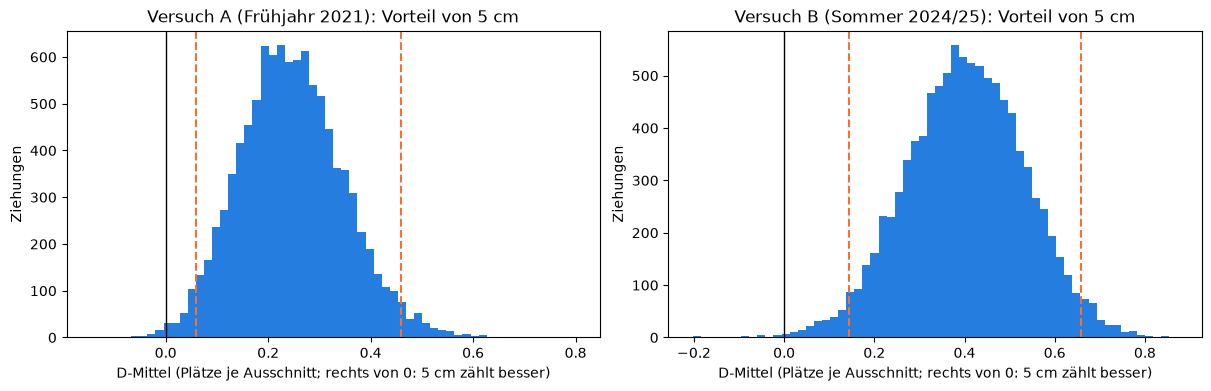

In [11]:
# Abbildung: Verteilung von D-Mittel aus dem Bootstrap, je Versuch; gestrichelt die Grenzen des 95-%-Intervalls
fig, achsen = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, versuch in zip(achsen, VERSUCHE):
    ax.hist(verteilungen[versuch], bins=60, color="#257de0")
    ax.axvline(0, color="black", linewidth=1)                        # kein Unterschied
    for grenze in [bootstrap.intervall_unten[versuch], bootstrap.intervall_oben[versuch]]:
        ax.axvline(grenze, color="#f47230", linestyle="--", linewidth=1.5)
    ax.set_title(f"Versuch {versuch} ({VERSUCHE[versuch]['name']}): Vorteil von 5 cm")
    ax.set_xlabel("D-Mittel (Plätze je Ausschnitt; rechts von 0: 5 cm zählt besser)"); ax.set_ylabel("Ziehungen")
fig.savefig(ABB / "10_bootstrap.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Die Verteilung der 10'000 Werte von $\bar D$. Die schwarze Linie steht bei 0 (kein Unterschied), die gestrichelten Linien begrenzen das 95-%-Intervall. Liegt die 0 **ausserhalb** des Intervalls, ist der Unterschied zwischen 5 cm und 10 cm mit diesen Testblöcken belegt. Liegt sie **innerhalb**, kann er Zufall sein.

**Einschränkung.** Das 10-cm-Bild ist aus dem 5-cm-Bild gerechnet (Mittel von 2 × 2 Pixeln). Ein echtes 10-cm-Bild wäre zusätzlich unschärfer; der Versuch zeigt also eher, was mit 10 cm **höchstens** möglich ist (`01b`, 7.9).

## 5. Die Zähltabelle im Vergleichsraum

Jetzt nur noch der **Vergleichsraum**: Felder im Strassenraum und im Gebiet. Nur hier gibt es amtliche Zahlen. Eine Tabelle mit festen Zeilen (`01b`, 8.5 D9); jede Spalte ist ein Lauf, jede Zahl eine Summe über alle Testausschnitte.

| Zeile | Bedeutung |
| --- | --- |
| Ground Truth: sichtbar | Felder, die im Bild zu sehen sind. Das kann ein Netz höchstens finden |
| … davon `✕`, davon `?` | so viele der sichtbaren Felder sind Sonderfelder (Taxi, Polizei, Feld mit Kreuz; Invalidenparkplatz) |
| Methode: erkannt | gezählte Plätze der Methode (je Ausschnitt gerundet, dann summiert) |
| amtlich | Punkte der amtlichen Daten desselben Jahres |
| Ground Truth: verdeckt, belegt | im Bild nicht zu sehen, aber belegt (anderes Bild oder DAV) |
| Methode: unter Verdeckung gemeldet | was das Netz auf verdeckten Stellen meldet; zählt nicht als erkannt |
| Ground Truth: einzeln stehend | sichtbare Felder ohne Reihe; nicht ausgewertet |
| Ground Truth: unsicher | zum Beispiel Baustelle; nicht gezählt |
| Streifen: von Hand geschätzt / gemeldet | Linien und durchgezogene Bereiche (alle, nicht nur Vergleichsraum); zählen nicht |

In [12]:
summe = zaehlung.groupby("lauf").sum(numeric_only=True).loc[LAEUFE]           # Summen über alle Testausschnitte je Lauf
zaehltabelle = pd.DataFrame({
    "Ground Truth: sichtbar": summe.wahr_vergleich,
    "… davon ✕": summe.wahr_kreuz_vergleich,
    "… davon ?": summe.wahr_fragezeichen_vergleich,
    "Methode: erkannt": summe.gezaehlt_vergleich,
    "amtlich": summe.amtlich,
    "Ground Truth: verdeckt, belegt": summe.wahr_verdeckt_belegt_vergleich,
    "Methode: unter Verdeckung gemeldet": summe.aeq_verdeckt_vergleich.round(1),
    "Ground Truth: einzeln stehend": summe.wahr_einzeln_vergleich,
    "Ground Truth: unsicher": summe.wahr_unsicher_vergleich,
    "Streifen: von Hand geschätzte Plätze": summe.wahr_streifen,
    "Streifen: gemeldet": summe.aeq_streifen.round(1),
}).T
zaehltabelle

lauf,A_5cm,A_10cm,B_5cm,B_10cm
Ground Truth: sichtbar,360.0,360.0,266.0,266.0
… davon ✕,30.0,30.0,24.0,24.0
… davon ?,0.0,0.0,0.0,0.0
Methode: erkannt,351.0,336.0,258.0,210.0
amtlich,354.0,354.0,275.0,275.0
"Ground Truth: verdeckt, belegt",3.0,3.0,46.0,46.0
Methode: unter Verdeckung gemeldet,1.1,0.7,15.0,9.5
Ground Truth: einzeln stehend,8.0,8.0,1.0,1.0
Ground Truth: unsicher,10.0,10.0,35.0,35.0
Streifen: von Hand geschätzte Plätze,58.0,58.0,55.0,55.0


## 6. Das Delta und woraus es besteht

**Das Delta** ist der Unterschied zwischen dem, was die Methode zählt, und der amtlichen Zahl:

$$\text{Delta} = \text{Methode} - \text{amtlich}$$

Aus dem Delta allein lässt sich nicht sagen, wer recht hat. Mit der eigenen Ground Truth lässt es sich aber in drei Teile zerlegen (`01b`, 7.9). Die drei Teile ergeben zusammen genau das Delta:

| Teil | Rechnung | bedeutet |
| --- | --- | --- |
| **1. Fehler der Methode** | Methode − sichtbare Felder | Was die Methode an sichtbaren Feldern zu viel oder zu wenig zählt |
| **2. Nicht sichtbar** | −(verdeckt, belegt + einzeln stehend) | Felder, die es gibt, die das Netz aber nicht zählen konnte oder die nicht ausgewertet wurden |
| **3. Ground Truth gegen amtlich** | (sichtbar + verdeckt, belegt + einzeln) − amtlich | Unterschied zwischen dem, was der Auftraggeber im Bild belegt hat, und den amtlichen Daten |

**Vorsicht beim Lesen.** Die Teile haben verschiedene Vorzeichen und können sich aufheben. Ein kleines Delta heisst darum nicht, dass die Methode genau zählt. Aussagekräftig sind die drei Teile einzeln.

Vorher: Summen je Lauf → nachher: Delta und seine drei Teile je Lauf.

In [13]:
belegt = summe.wahr_vergleich + summe.wahr_verdeckt_belegt_vergleich + summe.wahr_einzeln_vergleich   # alle belegten Felder laut Ground Truth
delta = pd.DataFrame({
    "methode": summe.gezaehlt_vergleich,
    "amtlich": summe.amtlich,
    "delta": summe.gezaehlt_vergleich - summe.amtlich,
    "teil_1_fehler_der_methode": summe.gezaehlt_vergleich - summe.wahr_vergleich,
    "teil_2_nicht_sichtbar": -(summe.wahr_verdeckt_belegt_vergleich + summe.wahr_einzeln_vergleich),
    "teil_3_ground_truth_gegen_amtlich": belegt - summe.amtlich,
})
assert (delta.delta == delta.teil_1_fehler_der_methode + delta.teil_2_nicht_sichtbar + delta.teil_3_ground_truth_gegen_amtlich).all()   # die Teile ergeben das Delta
delta["delta_in_%_von_amtlich"] = (100 * delta.delta / delta.amtlich).round(1)
delta

,methode,amtlich,delta,teil_1_fehler_der_methode,teil_2_nicht_sichtbar,teil_3_ground_truth_gegen_amtlich,delta_in_%_von_amtlich
lauf,,,,,,,
A_5cm,351,354,-3,-9,-11,17,-0.8
A_10cm,336,354,-18,-24,-11,17,-5.1
B_5cm,258,275,-17,-8,-47,38,-6.2
B_10cm,210,275,-65,-56,-47,38,-23.6


**Wie sicher ist das Delta?** Wieder der Bootstrap über die Testblöcke: Für jede Ziehung wird das Delta in Prozent der amtlichen Zahl neu gerechnet (Summe Methode ÷ Summe amtlich − 1, über die gezogenen Blöcke).

In [14]:
zeilen = []
rng = np.random.default_rng(SEED)
for lauf in LAEUFE:
    je_block = zaehlung[zaehlung.lauf == lauf].groupby("block")[["gezaehlt_vergleich", "amtlich"]].sum()   # Summen je Testblock
    gezogen = rng.integers(0, len(je_block), size=(ZIEHUNGEN, len(je_block)))                              # Nummern der gezogenen Blöcke
    verhaeltnis = je_block.gezaehlt_vergleich.values[gezogen].sum(axis=1) / je_block.amtlich.values[gezogen].sum(axis=1) - 1
    unten, oben = np.percentile(100 * verhaeltnis, [2.5, 97.5])
    zeilen.append({"lauf": lauf, "delta_%": delta["delta_in_%_von_amtlich"][lauf], "intervall_unten_%": round(unten, 1), "intervall_oben_%": round(oben, 1)})
delta_unsicherheit = pd.DataFrame(zeilen).set_index("lauf")
delta.join(delta_unsicherheit[["intervall_unten_%", "intervall_oben_%"]]).to_csv(ERG / "auswertung_delta.csv")
delta_unsicherheit

,delta_%,intervall_unten_%,intervall_oben_%
lauf,,,
A_5cm,-0.8,-5.1,3.3
A_10cm,-5.1,-14.8,2.7
B_5cm,-6.2,-30.1,17.4
B_10cm,-23.6,-59.7,-0.5


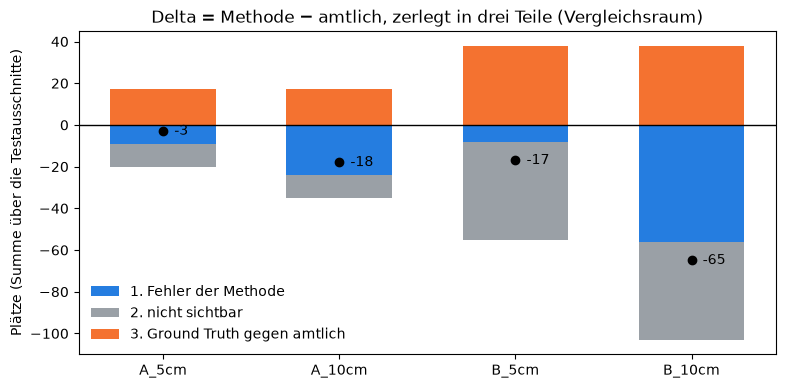

In [15]:
# Abbildung: das Delta je Lauf, zerlegt in seine drei Teile (gestapelte Balken); der schwarze Punkt ist das Delta
teile = {"teil_1_fehler_der_methode": ("1. Fehler der Methode", "#257de0"), "teil_2_nicht_sichtbar": ("2. nicht sichtbar", "#9aa0a6"),
         "teil_3_ground_truth_gegen_amtlich": ("3. Ground Truth gegen amtlich", "#f47230")}
fig, ax = plt.subplots(figsize=(9, 4.2))
for nummer, lauf in enumerate(LAEUFE):
    unten_plus, unten_minus = 0, 0                                    # positive Teile stapeln nach oben, negative nach unten
    for spalte, (name, farbe) in teile.items():
        wert = delta[spalte][lauf]
        start = unten_plus if wert >= 0 else unten_minus
        ax.bar(nummer, wert, bottom=start, color=farbe, width=0.6, label=name if nummer == 0 else None)
        if wert >= 0:
            unten_plus += wert
        else:
            unten_minus += wert
    ax.plot(nummer, delta.delta[lauf], "o", color="black")           # das Delta selbst
    ax.annotate(f"{delta.delta[lauf]:+d}", (nummer, delta.delta[lauf]), xytext=(8, 0), textcoords="offset points", va="center")
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(range(len(LAEUFE))); ax.set_xticklabels(LAEUFE)
ax.set_ylabel("Plätze (Summe über die Testausschnitte)")
ax.set_title("Delta = Methode − amtlich, zerlegt in drei Teile (Vergleichsraum)")
ax.legend(frameon=False)
fig.savefig(ABB / "10_delta.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jeder Balken ist ein Lauf. Die farbigen Stücke sind die drei Teile; der schwarze Punkt ist ihre Summe, das Delta. So sieht man auf einen Blick, ob das Delta vor allem von der Methode kommt (blau), von Feldern, die im Bild nicht zu sehen sind (grau), oder vom Unterschied zwischen Ground Truth und amtlichen Daten (orange).

## 7. Fehler ansehen

Der Testausschnitt mit den meisten sichtbaren Feldern im Bild 2021, für alle vier Läufe. Grün: richtig erkannt. Rot: Fehlmeldung. Blau: übersehen. Grau: nicht bewertet.

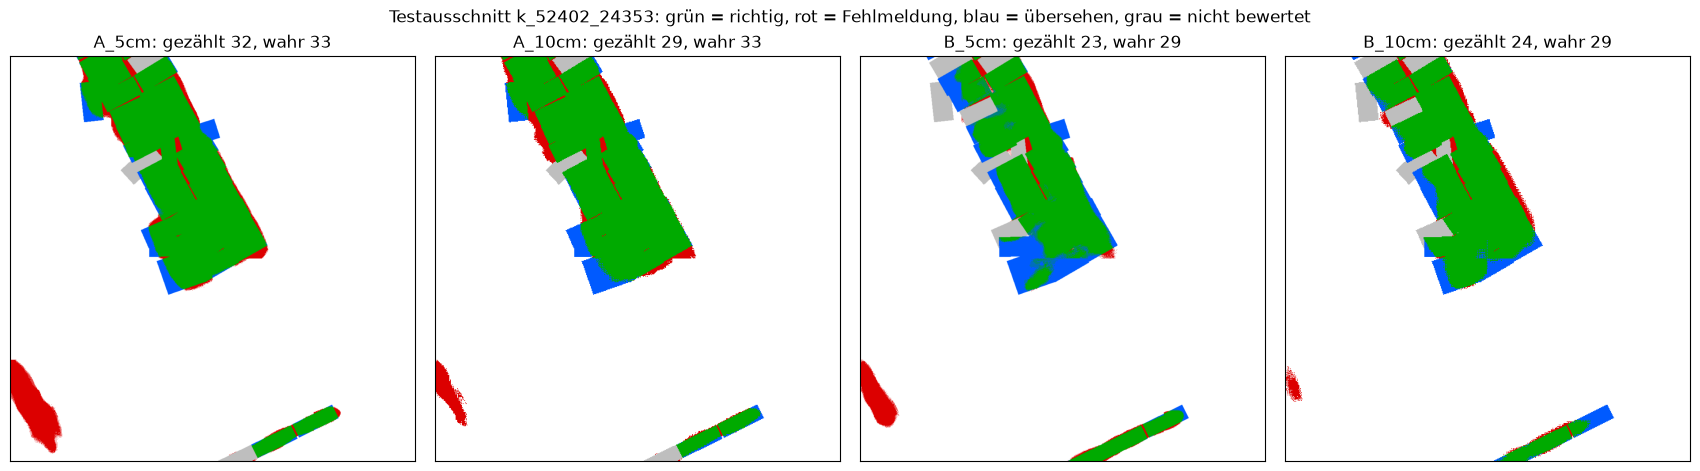

In [16]:
kachel = zaehlung[zaehlung.lauf == "A_5cm"].set_index("kachel").wahr.idxmax()     # Ausschnitt mit den meisten sichtbaren Feldern
fig, achsen = plt.subplots(1, 4, figsize=(17, 4.6), layout="constrained")
for ax, lauf in zip(achsen, LAEUFE):
    gemeldet = np.load(ERG / "masken" / lauf / f"{kachel}.npz")["gemeldet"]       # Meldung (Notebook 08)
    kategorie = np.load(VERARB / "loesung" / lauf / f"{kachel}.npz")["kategorie"] # Kategorie je Pixel (Notebook 05)
    bild = np.full(gemeldet.shape + (3,), 255, dtype="uint8")                     # weisses Bild
    bild[kategorie > 1] = (190, 190, 190)                                         # nicht bewertet: grau
    bild[gemeldet & (kategorie == 1)] = (0, 170, 0)                               # richtig erkannt: grün
    bild[gemeldet & (kategorie == 0)] = (220, 0, 0)                               # Fehlmeldung: rot
    bild[~gemeldet & (kategorie == 1)] = (0, 90, 255)                             # übersehen: blau
    zeile = zaehlung[(zaehlung.lauf == lauf) & (zaehlung.kachel == kachel)].iloc[0]
    ax.imshow(bild); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{lauf}: gezählt {zeile.gezaehlt}, wahr {zeile.wahr}")
fig.suptitle(f"Testausschnitt {kachel}: grün = richtig, rot = Fehlmeldung, blau = übersehen, grau = nicht bewertet")
fig.savefig(ABB / "10_fehler.png", dpi=110, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Dieselbe Stelle in allen vier Läufen. Blaue Flächen sind sichtbare Felder, die das Netz nicht gemeldet hat; rote Flächen hat es gemeldet, obwohl die Lösung dort kein Feld hat.

## 8. Alles in einer Tabelle

In [17]:
gesamt = flaeche.join(anzahl[["wahr", "gezaehlt", "mae", "bias", "mae_formel", "mae_b0", "mae_b1", "ausschnitte_mit_feldern", "mae_mit_feldern", "felder_je_ausschnitt_mit_feldern", "wahr_kreuz", "wahr_fragezeichen"]]).join(nach_form[["trefferquote_gewoehnlich", "trefferquote_sonder"]]).join(delta[["methode", "amtlich", "delta"]]).join(delta_unsicherheit)
gesamt.to_csv(ERG / "auswertung_laeufe.csv")
gesamt.round(3)

,iou,genauigkeit,trefferquote,flaechenverhaeltnis,wahr,gezaehlt,mae,bias,mae_formel,mae_b0,...,wahr_kreuz,wahr_fragezeichen,trefferquote_gewoehnlich,trefferquote_sonder,methode,amtlich,delta,delta_%,intervall_unten_%,intervall_oben_%
lauf,,,,,,,,,,,,,,,,,,,,,
A_5cm,0.618,0.783,0.745,0.951,708,664,0.861,-0.062,0.321,5.168,...,44,7,0.762,0.523,351,354,-3,-0.8,-5.1,3.3
A_10cm,0.582,0.774,0.701,0.906,708,626,1.109,-0.116,0.314,5.168,...,44,7,0.724,0.399,336,354,-18,-5.1,-14.8,2.7
B_5cm,0.569,0.759,0.694,0.914,500,454,0.847,-0.092,0.190,3.650,...,30,5,0.711,0.466,258,275,-17,-6.2,-30.1,17.4
B_10cm,0.487,0.738,0.589,0.797,500,395,1.263,-0.210,0.190,3.650,...,30,5,0.615,0.225,210,275,-65,-23.6,-59.7,-0.5


## 9. Kurzfassung in Sätzen

Die folgende Zelle schreibt die Antworten auf die vier Fragen als Sätze. Jede Zahl darin stammt aus den Tabellen dieses Notebooks; die Sätze ändern sich also mit, wenn neu gerechnet wird.

In [18]:
for versuch, angaben in VERSUCHE.items():
    fein, grob = f"{versuch}_5cm", f"{versuch}_10cm"
    print(f"Versuch {versuch} ({angaben['name']})")
    print(f"  1. Fläche: IoU {flaeche.iou[fein]:.2f} bei 5 cm und {flaeche.iou[grob]:.2f} bei 10 cm. "
          f"Gemeldete ÷ wahre Fläche: {flaeche.flaechenverhaeltnis[fein]:.2f} und {flaeche.flaechenverhaeltnis[grob]:.2f}.")
    print(f"  2. Anzahl je Ausschnitt: MAE {anzahl.mae[fein]:.2f} (5 cm) und {anzahl.mae[grob]:.2f} (10 cm) Plätze; "
          f"Untergrenze (Formel am Lösungsblatt) {anzahl.mae_formel[fein]:.2f}, Baseline B0 {anzahl.mae_b0[fein]:.2f}, B1 {anzahl.mae_b1[fein]:.2f}. Insgesamt gezählt: {anzahl.bias[fein]:+.0%} (5 cm) und {anzahl.bias[grob]:+.0%} (10 cm) gegenüber der Ground Truth.")
    print(f"     Nur die {anzahl.ausschnitte_mit_feldern[fein]} Ausschnitte mit Feldern (im Mittel {anzahl.felder_je_ausschnitt_mit_feldern[fein]:.1f} Felder): MAE {anzahl.mae_mit_feldern[fein]:.2f} (5 cm) und {anzahl.mae_mit_feldern[grob]:.2f} (10 cm) Plätze.")
    print(f"     Sonderfelder: {anzahl.wahr_kreuz[fein]} mit ✕ und {anzahl.wahr_fragezeichen[fein]} mit ? unter den {anzahl.wahr[fein]} sichtbaren Feldern. "
          f"Trefferquote der Fläche bei 5 cm: {nach_form.trefferquote_sonder[fein]:.2f} auf Sonderfeldern, {nach_form.trefferquote_gewoehnlich[fein]:.2f} auf gewöhnlichen Feldern.")
    zeile = bootstrap.loc[versuch]
    if zeile.intervall_ohne_null:
        urteil = ("5 cm zählt besser" if zeile.D_mittel > 0 else "10 cm zählt besser") + "; das Intervall enthält die 0 nicht"
    else:
        urteil = "der Unterschied kann Zufall sein; das Intervall enthält die 0"
    print(f"  3. 5 cm gegen 10 cm: Vorteil von 5 cm {zeile.D_mittel:+.2f} Plätze je Ausschnitt (95-%-Intervall {zeile.intervall_unten:+.2f} bis {zeile.intervall_oben:+.2f}): {urteil}.")
    for lauf in [fein, grob]:
        d = delta.loc[lauf, ["methode", "amtlich", "delta", "teil_1_fehler_der_methode", "teil_2_nicht_sichtbar", "teil_3_ground_truth_gegen_amtlich"]].astype(int)   # ganze Zahlen dieser Zeile
        print(f"  4. Delta {lauf}: Methode {d.methode} gegen amtlich {d.amtlich} = {d.delta:+d} Plätze ({delta_unsicherheit['delta_%'][lauf]:+.1f} %, "
              f"95-%-Intervall {delta_unsicherheit['intervall_unten_%'][lauf]:+.1f} bis {delta_unsicherheit['intervall_oben_%'][lauf]:+.1f} %). "
              f"Teile: Fehler der Methode {d.teil_1_fehler_der_methode:+d}, nicht sichtbar {d.teil_2_nicht_sichtbar:+d}, Ground Truth gegen amtlich {d.teil_3_ground_truth_gegen_amtlich:+d}.")
    print("     Die Teile heben sich zum Teil auf: Ein kleines Delta heisst nicht, dass genau gezählt wurde.")
    print()

Versuch A (Frühjahr 2021)
  1. Fläche: IoU 0.62 bei 5 cm und 0.58 bei 10 cm. Gemeldete ÷ wahre Fläche: 0.95 und 0.91.
  2. Anzahl je Ausschnitt: MAE 0.86 (5 cm) und 1.11 (10 cm) Plätze; Untergrenze (Formel am Lösungsblatt) 0.32, Baseline B0 5.17, B1 5.17. Insgesamt gezählt: -6% (5 cm) und -12% (10 cm) gegenüber der Ground Truth.
     Nur die 77 Ausschnitte mit Feldern (im Mittel 9.2 Felder): MAE 1.34 (5 cm) und 1.82 (10 cm) Plätze.
     Sonderfelder: 44 mit ✕ und 7 mit ? unter den 708 sichtbaren Feldern. Trefferquote der Fläche bei 5 cm: 0.52 auf Sonderfeldern, 0.76 auf gewöhnlichen Feldern.
  3. 5 cm gegen 10 cm: Vorteil von 5 cm +0.25 Plätze je Ausschnitt (95-%-Intervall +0.06 bis +0.46): 5 cm zählt besser; das Intervall enthält die 0 nicht.
  4. Delta A_5cm: Methode 351 gegen amtlich 354 = -3 Plätze (-0.8 %, 95-%-Intervall -5.1 bis +3.3 %). Teile: Fehler der Methode -9, nicht sichtbar -11, Ground Truth gegen amtlich +17.
  4. Delta A_10cm: Methode 336 gegen amtlich 354 = -18 Plätze 

## Grenzen dieser Aussage

Diese Punkte gehören zu jeder Zahl oben. Keiner davon wurde "weggerechnet".

| Grenze | Folge |
| --- | --- |
| **Ein Versuch, kein Zielwert.** | Die Zahlen beschreiben, was diese Methode mit diesen Daten leistet. Sie sind weder amtlich noch für Planung oder Recht geeignet. |
| **15 Testblöcke.** | Die Intervalle sind breit. Ein Unterschied, dessen Intervall die 0 enthält, ist nicht belegt. |
| **Wenige Blöcke tragen viel.** | Die sichtbaren Felder sind ungleich verteilt (Abschnitt 2, Schritt 2). Die Kennzahlen über alle Pixel werden von den Blöcken mit viel Parkfläche bestimmt; je Block streut die IoU stark. |
| **Viele leere Ausschnitte.** | Rund die Hälfte der Testausschnitte hat kein sichtbares Feld. Das macht die MAE über alle Ausschnitte klein; die MAE dort, wo es Felder gibt, steht daneben (Abschnitt 3, Schritt 4). |
| **Ein Lernlauf je Variante.** | Jedes der vier Netze dieser Auswertung wurde genau einmal gelernt (Seed 42). Der Bootstrap bildet nur die Auswahl der Testblöcke ab, nicht den Zufall beim Lernen. Einzige Wiederholung: Das 10-cm-Netz des Bildes 2021 wurde für die Gegenprobe ein zweites Mal gelernt (Notebook 11); der Vorteil von 5 cm bleibt dort bestehen. Für das Bild 2024/25 und für die 5-cm-Netze gibt es keine Wiederholung. |
| **Das Delta ist eine Summe mit Gegenrechnung.** | Seine drei Teile haben verschiedene Vorzeichen (Abschnitt 6). Ein kleines Delta kann aus grösseren Teilen entstehen, die sich aufheben. |
| **Ground Truth aus einem Durchgang einer Person.** | In den Kontroll-Ausschnitten wurden 92 % der verborgenen DAV-Felder innerhalb von 2,5 m gefunden (`ground_truth_pruefen`). Für Felder in Innenhöfen gibt es keine Gegenprobe. Eine Wiederholungsprobe steht aus (`01b`, 8.5 D10). |
| **Kästchen aus Regeln.** | Klasse und Richtung eines Kästchens folgen aus der Reihe der Ringe; an der DAV geprüft stimmt die Klasse bei 96 % (Notebook 03). Ein falsches Kästchen ist eine falsche Lösung an dieser Stelle. |
| **Die Zählformel hat einen eigenen Fehler.** | Selbst am perfekten Lösungsblatt liegt sie je Ausschnitt etwas daneben (Spalte `mae_formel` in Abschnitt 3; in den Lernblöcken rund 0,4 Plätze, Notebook 05). |
| **Epochen nach Zeitrahmen.** | 16 Epochen (5 cm) und 40 Epochen (10 cm) waren vorab festgelegt (`01b`, Abschnitt 11, E10). Im Lernlauf vom 27.11.2026 ist bei `A_10cm` die beste Epoche die letzte; nach `01b`, 7.4 ist dann nicht belegt, dass das Maximum erreicht ist. Im ersten Lauf wurde nicht verlängert. Die Kurven aller vier Läufe sind im letzten Viertel flach (Notebook 07, Abschnitt 8). Nachgeholt als Gegenprobe: Mit 60 statt 40 Epochen wird das Netz auf der Validierung nicht besser (Notebook 07, Abschnitt 11), und in den Testblöcken ändert sich die Antwort auf die Leitfrage nicht (Notebook 11). |
| **Test und Validierung sind verschiedene Blöcke.** | Die IoU in den Testblöcken (Abschnitt 2) liegt bei allen vier Läufen höher als auf der Validierung (Notebook 07, Abschnitt 9). Die Ursache ist nicht untersucht. In Frage kommen die anderen Blöcke (es gibt nur 9 Validierblöcke) und die Vorhersage mit überlappenden Fenstern (Notebook 08). |
| **10 cm ist gerechnet.** | Das 10-cm-Bild ist das gemittelte 5-cm-Bild. Ein echtes 10-cm-Bild wäre unschärfer. |
| **Versuch A und B unterscheiden sich in vielem.** | Belaubung, Jahr, Sonnenstand, Autos und amtliche Daten sind verschieden. Ein Unterschied zwischen A und B lässt sich nicht einer einzelnen Ursache zuschreiben (`01b`, 7.9). |
| **Teil 3 des Deltas besteht vor allem aus gelben Markierungen.** | Der Auftraggeber hat 30 Felder beurteilt, die die Ground Truth im Strassenraum hat und die amtlichen Daten nicht (Notebook `stichprobe_strassenraum`). Nur wenige sind gewöhnliche Parkfelder; die meisten sind reservierte oder private Felder und Markierungen mit gelbem Kreuz, auf denen nicht parkiert werden darf. Teil 3 darf darum nicht als "Parkplätze, die den amtlichen Daten fehlen" gelesen werden. Der Auftraggeber hat am 27.11.2026 entschieden, die festgelegte Methodik beizubehalten; gelbe Markierungen zählen in diesem Durchgang weiter mit (`01b`, Abschnitt 11.2). |
| **Sonderfelder zählen mit.** | Felder mit `✕` (Taxi, Polizei, Feld mit Kreuz) und `?` (Invalidenparkplatz) zählen wie gewöhnliche Felder (`01b`, 8.5 D4). Wie viele es sind, steht in Abschnitt 3 (Schritt 5) und in der Zähltabelle (Abschnitt 5); wie gut das Netz ihre Fläche findet, in Abschnitt 2 (Schritt 3). Herausgerechnet werden sie nicht. |
| **Nicht ausgewertet.** | Einzeln stehende Felder, Streifen, unsichere Stellen und alles ausserhalb des Vergleichsraums gehen nicht ins Delta ein; sie stehen in der Zähltabelle (Abschnitt 5). |

## Wie es weitergeht

Notebook 11 ist ein Nachtrag: Es prüft, ob die Antwort auf die Leitfrage im Bild 2021 hält, wenn das 10-cm-Netz länger lernt. Das Notebook `stichprobe_strassenraum` bereitet eine Stichprobe vor, mit der sich Teil 3 des Deltas besser einordnen lässt.

Offen und in `01b`, Abschnitt 11 (E12), festgehalten: Prüfung "leer gegen belegt" (stützt sich das Netz auf Autos?), Lernkurve über die Datenmenge, Wiederholungsprobe der Ground Truth, Zusammenlegen beider Jahre, Karte des ganzen Gebiets.